PHẦN CHUẨN BỊ: THIẾT LẬP MÔI TRƯỜNG

In [13]:
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt

# Chọn thiết bị (GPU nếu có, không thì CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# =====================================================================
# BÊ NGUYÊN MÔI TRƯỜNG MOS-DRIVEN CỦA CHÚNG TA VÀO ĐÂY
# =====================================================================
class MosVideoRoutingEnv(gym.Env):
    metadata = {"render_modes":["human"]}

    def __init__(self):
        super(MosVideoRoutingEnv, self).__init__()
        self.max_steps = 200
        self.current_step = 0
        self.paths = {0:[1, 8], 1: [2, 6, 9], 2: [0, 3, 8], 3:[2, 5, 8]}
        self.action_space = spaces.Discrete(4)
        
        # State Size: 20 (10 links *[Delay, Loss])
        low_bound = np.zeros(20, dtype=np.float32)
        high_bound = np.array([500.0, 100.0] * 10, dtype=np.float32)
        self.observation_space = spaces.Box(low=low_bound, high=high_bound, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        self.state = np.zeros(20, dtype=np.float32)
        for i in range(10):
            self.state[i*2] = np.random.uniform(10.0, 20.0)
            self.state[i*2+1] = 0.0
        return self.state, {}

    def step(self, action):
        self.current_step += 1
        for i in range(10):
            self.state[i*2] = np.random.uniform(10.0, 25.0)
            self.state[i*2+1] = 0.0

        # Kịch bản kẹt xe ở Link 6 (thuộc Path 1)
        if 50 <= self.current_step <= 150:
            self.state[6*2] = np.random.uniform(150.0, 300.0)
            self.state[6*2+1] = np.random.uniform(5.0, 15.0)
            
        chosen_path_links = self.paths[action]
        total_delay = sum([self.state[i*2] for i in chosen_path_links])
        
        prob_success = 1.0
        for i in chosen_path_links:
            prob_success *= (1.0 - (self.state[i*2+1] / 100.0))
        total_loss_percent = (1.0 - prob_success) * 100.0
        
        # TÍNH MOS (Từ 1.0 đến 5.0)
        mos = 5.0 
        effective_delay = max(0, total_delay - 50.0)
        mos -= (effective_delay * 0.005) 
        mos -= (total_loss_percent * 0.2)
        mos = float(np.clip(mos, 1.0, 5.0))
        
        reward = mos # Dùng MOS làm Reward
        
        terminated = False
        truncated = self.current_step >= self.max_steps
        
        return self.state, reward, terminated, truncated, {"mos": mos}

Using device: cpu


Core Component - Replay Buffer

In [14]:
class ReplayBuffer:
    """Store and sample experiences for training DQN."""
    def __init__(self, capacity=10000):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, min(batch_size, len(self.buffer)))
        
        # Convert lists to numpy arrays
        states_np = np.array([t[0] for t in batch], dtype=np.float32)
        actions_np = np.array([t[1] for t in batch], dtype=np.int64)
        rewards_np = np.array([t[2] for t in batch], dtype=np.float32)
        next_states_np = np.array([t[3] for t in batch], dtype=np.float32)
        dones_np = np.array([t[4] for t in batch], dtype=np.float32)
        
        # Convert to PyTorch Tensors
        states = torch.tensor(states_np, dtype=torch.float32, device=device)
        actions = torch.tensor(actions_np, dtype=torch.int64, device=device)
        rewards = torch.tensor(rewards_np, dtype=torch.float32, device=device)
        next_states = torch.tensor(next_states_np, dtype=torch.float32, device=device)
        dones = torch.tensor(dones_np, dtype=torch.float32, device=device)
        
        return states, actions, rewards, next_states, dones

    def __len__(self):
        return len(self.buffer)
        
print("v ReplayBuffer class defined (Customized for Routing)")

v ReplayBuffer class defined (Customized for Routing)


Core Component - DQN Network

In [15]:
class DQNNetwork(nn.Module):
    """Deep Q-Network for approximating Q-values (Video Routing)."""
    # Architecture: Input(20) -> Linear(128) -> ReLU -> Linear(64) -> ReLU -> Output(4)
    def __init__(self, state_size=20, action_size=4):
        super(DQNNetwork, self).__init__()
        self.fc1 = nn.Linear(state_size, 128)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()
        self.out = nn.Linear(64, action_size)

    def forward(self, state):
        x = self.fc1(state)
        x = self.relu1(x)
        x = self.fc2(x)
        x = self.relu2(x)
        q_values = self.out(x)
        return q_values

print("v DQNNetwork class defined (20 inputs -> 4 outputs)")

v DQNNetwork class defined (20 inputs -> 4 outputs)


DQN Agent - Complete Algorithm

In [16]:
class DQNAgent:
    def __init__(self, state_size=20, action_size=4, learning_rate=1e-3):
        self.state_size = state_size
        self.action_size = action_size
        
        self.gamma = 0.99
        self.epsilon = 1.0
        self.epsilon_min = 0.05
        self.epsilon_decay = 0.997
        
        self.q_network = DQNNetwork(state_size, action_size).to(device)
        self.target_network = DQNNetwork(state_size, action_size).to(device)
        self.target_network.load_state_dict(self.q_network.state_dict())
        self.target_network.eval()
        
        self.optimizer = optim.Adam(self.q_network.parameters(), lr=learning_rate)
        self.loss_fn = nn.MSELoss()
        
        self.replay_buffer = ReplayBuffer(capacity=10000)
        self.update_counter = 0

    def select_action(self, state, training=True):
        if training and random.random() < self.epsilon:
            return random.randint(0, self.action_size - 1)
            
        # KHÔNG DÙNG ONE-HOT ENCODING NHƯ FROZEN LAKE. 
        # Chuyển thẳng mảng state thành Tensor
        state_tensor = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
        with torch.no_grad():
            q_values = self.q_network(state_tensor)
        return q_values.argmax(dim=1).item()

    def store_transition(self, state, action, reward, next_state, done):
        # Đẩy thẳng state (vốn đã là mảng float 20 pt) vào buffer
        self.replay_buffer.push(state, action, reward, next_state, done)

    def train_step(self, batch_size=32):
        if len(self.replay_buffer) < batch_size:
            return # Chưa đủ mẫu để học
            
        states, actions, rewards, next_states, dones = self.replay_buffer.sample(batch_size)
        
        # 1. Tính Q_values hiện tại
        q_values = self.q_network(states).gather(1, actions.unsqueeze(1)).squeeze(1)
        
        # 2. Tính Q_target theo phương trình Bellman
        with torch.no_grad():
            next_q_values = self.target_network(next_states).max(dim=1)[0]
            target_q_values = rewards + self.gamma * next_q_values * (1 - dones)
            
        # 3. Tính Loss và Backpropagation
        loss = self.loss_fn(q_values, target_q_values)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        
        # 4. Cập nhật Target Network mỗi 100 bước
        self.update_counter += 1
        if self.update_counter % 100 == 0:
            self.target_network.load_state_dict(self.q_network.state_dict())

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

print("v DQNAgent class defined (Removed One-hot Encoding)")

v DQNAgent class defined (Removed One-hot Encoding)


Training DQN on Video Routing

In [17]:
env_train = MosVideoRoutingEnv()
agent = DQNAgent(state_size=20, action_size=4, learning_rate=1e-3)

num_episodes = 300 
batch_size = 64
episode_rewards = []
epsilon_history = [] # Lưu lại quá trình giảm epsilon

print(f"\n2.4: Training DQN for {num_episodes} episodes...")
print("-" * 60)

for episode in range(num_episodes):
    state, _ = env_train.reset()
    episode_reward = 0
    done = False
    
    while not done:
        action = agent.select_action(state, training=True)
        next_state, reward, terminated, truncated, _ = env_train.step(action)
        done = terminated or truncated
        
        agent.store_transition(state, action, reward, next_state, done)
        agent.train_step(batch_size)
        
        episode_reward += reward
        state = next_state
        
    agent.decay_epsilon()
    episode_rewards.append(episode_reward)
    epsilon_history.append(agent.epsilon)
    
    if (episode + 1) % 100 == 0:
        avg_reward = np.mean(episode_rewards[-100:])
        print(f"Episode {episode+1:4d}/{num_episodes} | Avg Reward: {avg_reward:.2f} | Epsilon: {agent.epsilon:.3f}")

print("\nTraining completed!")


2.4: Training DQN for 300 episodes...
------------------------------------------------------------
Episode  100/300 | Avg Reward: 924.31 | Epsilon: 0.740
Episode  200/300 | Avg Reward: 931.84 | Epsilon: 0.548
Episode  300/300 | Avg Reward: 938.97 | Epsilon: 0.406

Training completed!


In [12]:
import pandas as pd

# Tạo DataFrame lưu trữ kết quả
training_data = pd.DataFrame({
    'Episode': range(1, num_episodes + 1),
    'Total_Reward': episode_rewards,
    'Epsilon': epsilon_history
})

# Xuất ra file CSV
training_data.to_csv('dqn_training_log_1000ep.csv', index=False)
print("v Đã xuất dữ liệu huấn luyện ra file 'dqn_training_log_1000ep.csv'")

v Đã xuất dữ liệu huấn luyện ra file 'dqn_training_log_1000ep.csv'


Evaluation & Visualization


2.5: Evaluation with Greedy Policy (Testing Phase)
------------------------------------------------------------
Evaluation Results over 1000 episodes:
 Average MOS Score per step: 4.98 / 5.0

2.6: Visualization of Training Progress
------------------------------------------------------------


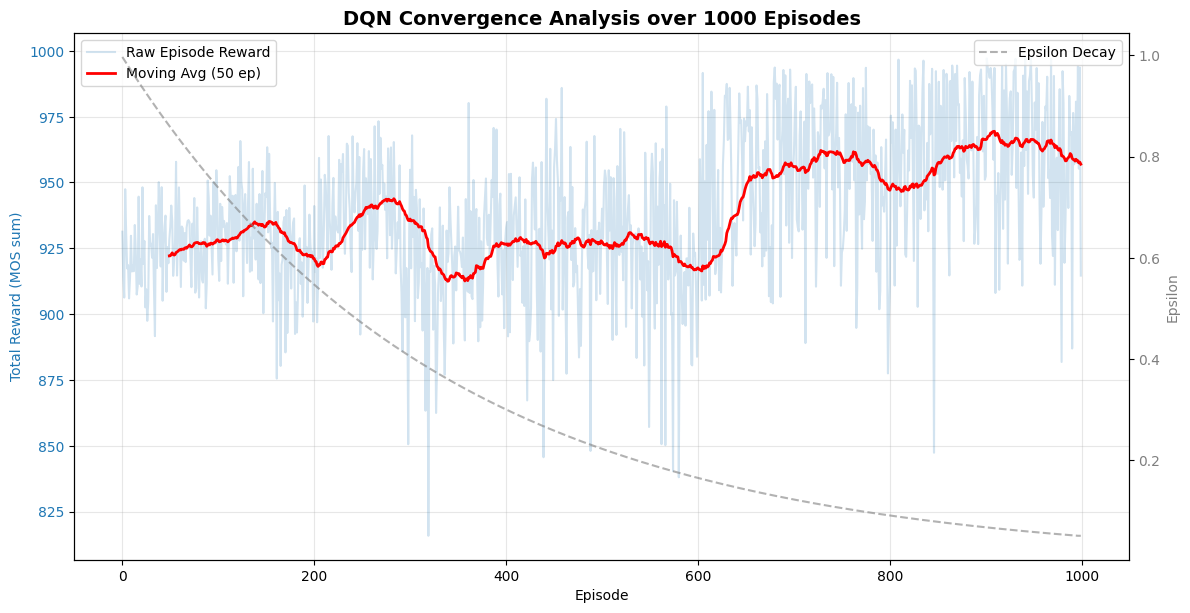

Đã lưu trọng số Pytorch Model thành 'dqn_pytorch_routing.pth'


In [13]:
# --- EVALUATION ---
print("\n2.5: Evaluation with Greedy Policy (Testing Phase)")
print("-" * 60)

eval_episodes = 1000
eval_rewards = []
avg_mos_scores =[]

for episode in range(eval_episodes):
    state, _ = env_train.reset()
    episode_reward = 0
    done = False
    step_count = 0
    
    while not done:
        # Tắt training (epsilon = 0), luôn chọn hành động tốt nhất
        action = agent.select_action(state, training=False)
        next_state, reward, terminated, truncated, info = env_train.step(action)
        done = terminated or truncated
        episode_reward += reward
        state = next_state
        step_count += 1
        
    eval_rewards.append(episode_reward)
    avg_mos_scores.append(episode_reward / step_count) # MOS trung bình của tập đó

print(f"Evaluation Results over {eval_episodes} episodes:")
print(f" Average MOS Score per step: {np.mean(avg_mos_scores):.2f} / 5.0")

# --- VISUALIZATION ---
print("\n2.6: Visualization of Training Progress")
print("-" * 60)

fig, ax1 = plt.subplots(figsize=(12, 6))

# Trục trái: Vẽ Reward
color = 'tab:blue'
ax1.set_xlabel('Episode')
ax1.set_ylabel('Total Reward (MOS sum)', color=color)
ax1.plot(episode_rewards, alpha=0.2, color=color, label='Raw Episode Reward')

# Vẽ đường trung bình trượt (Moving Average) - cửa sổ 50 episodes
window = 50
ma_rewards = np.convolve(episode_rewards, np.ones(window)/window, mode='valid')
ax1.plot(range(window-1, len(episode_rewards)), ma_rewards, color='red', linewidth=2, label=f'Moving Avg ({window} ep)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, alpha=0.3)

# Trục phải: Vẽ Epsilon (để thấy sự đánh đổi Khám phá - Khai thác)
ax2 = ax1.twinx() 
color = 'tab:gray'
ax2.set_ylabel('Epsilon', color=color)
ax2.plot(epsilon_history, color=color, linestyle='--', alpha=0.6, label='Epsilon Decay')
ax2.tick_params(axis='y', labelcolor=color)

fig.tight_layout()
plt.title('DQN Convergence Analysis over 1000 Episodes', fontsize=14, fontweight='bold')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.show()

fig.savefig("convergence_1000ep.png", dpi=300)

# Lưu Model theo chuẩn PyTorch để nhúng vào Ubuntu nếu cần
torch.save(agent.q_network.state_dict(), "dqn_pytorch_routing.pth")
print("Đã lưu trọng số Pytorch Model thành 'dqn_pytorch_routing.pth'")

Huấn luyện và Xuất mô hình trên Windows (Jupyter Notebook)

Thu thập dữ liệu so sánh (Chạy RL, Greedy, Random)

In [16]:
def run_evaluation(policy_type="RL"):
    env_eval = MosVideoRoutingEnv()
    obs, _ = env_eval.reset()
    done = False
    history = {"mos": [], "delay": [], "loss": [], "actions": []}
    
    while not done:
        if policy_type == "RL":
            action = agent.select_action(obs, training=False)
        elif policy_type == "Greedy":
            action = 1 # Luôn chọn Path 1 (Đường ngắn nhất mặc định)
        else:
            action = random.randint(0, 3)
            
        obs, reward, terminated, truncated, info = env_eval.step(action)
        done = terminated or truncated
        
        # Tính toán thông số thực tế từ môi trường để vẽ
        chosen_path = env_eval.paths[action]
        d = sum([obs[i*2] for i in chosen_path])
        l = (1 - np.prod([(1 - obs[i*2+1]/100) for i in chosen_path])) * 100
        
        history["mos"].append(info["mos"])
        history["delay"].append(d)
        history["loss"].append(l)
        history["actions"].append(action)
    return history

# Thu thập dữ liệu
rl_stats = run_evaluation("RL")
greedy_stats = run_evaluation("Greedy")
random_stats = run_evaluation("Random")

 Vẽ biểu đồ so sánh Hiệu năng

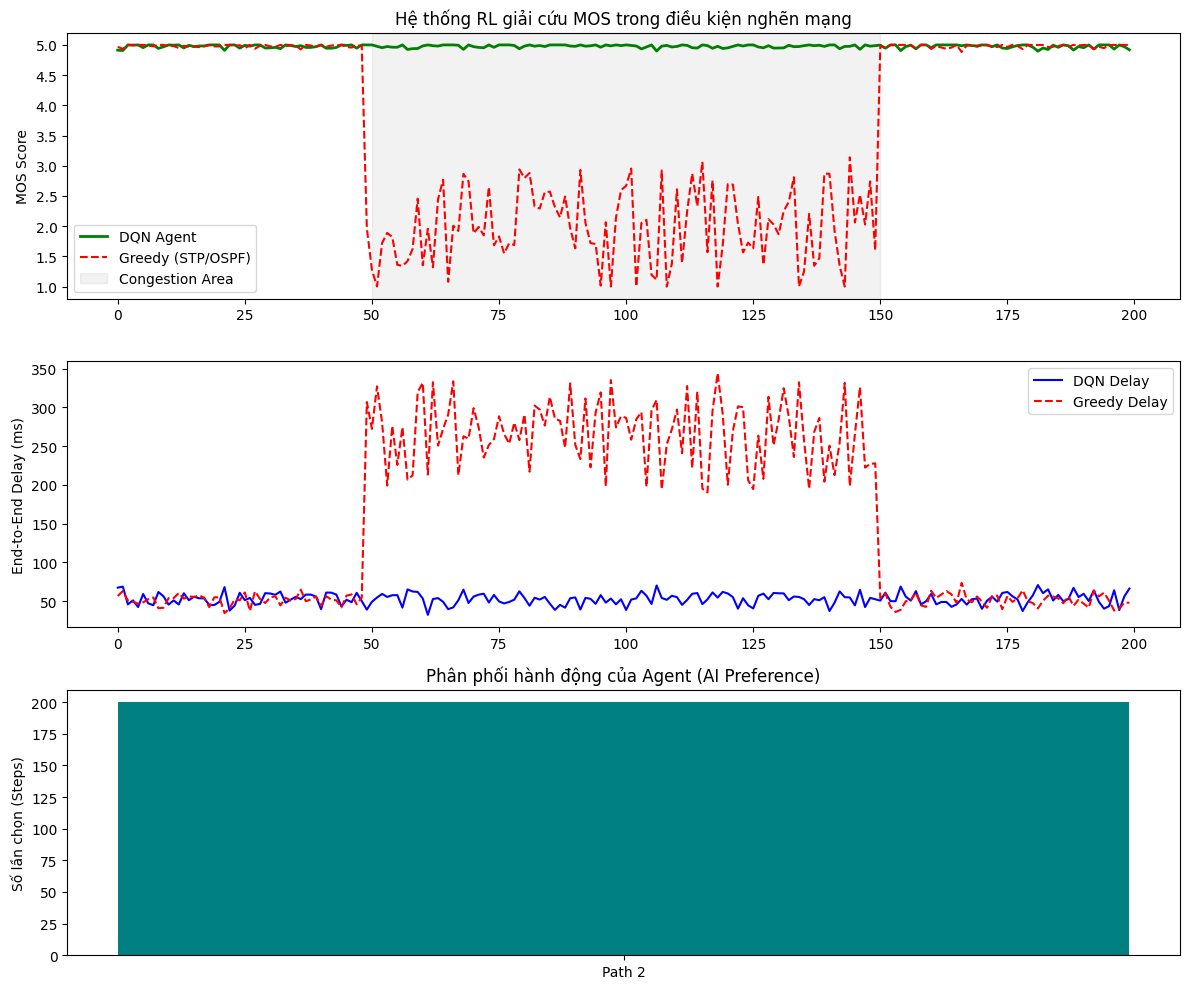

In [17]:
plt.figure(figsize=(12, 10))

# Subplot 1: MOS Comparison
plt.subplot(3, 1, 1)
plt.plot(rl_stats["mos"], label="DQN Agent", color='green', linewidth=2)
plt.plot(greedy_stats["mos"], label="Greedy (STP/OSPF)", color='red', linestyle='--')
plt.axvspan(50, 150, color='gray', alpha=0.1, label='Congestion Area')
plt.ylabel("MOS Score")
plt.title("Hệ thống RL giải cứu MOS trong điều kiện nghẽn mạng")
plt.legend()

# Subplot 2: Delay Comparison
plt.subplot(3, 1, 2)
plt.plot(rl_stats["delay"], color='blue', label="DQN Delay")
plt.plot(greedy_stats["delay"], color='red', linestyle='--', label="Greedy Delay")
plt.ylabel("End-to-End Delay (ms)")
plt.legend()

# Subplot 3: Action Distribution (Hành động của AI)
plt.subplot(3, 1, 3)
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99']
unique, counts = np.unique(rl_stats["actions"], return_counts=True)
plt.bar([f"Path {i}" for i in unique], counts, color='teal')
plt.ylabel("Số lần chọn (Steps)")
plt.title("Phân phối hành động của Agent (AI Preference)")

plt.tight_layout()
plt.show()

Cập nhật Environment (Kịch bản nghẽn động)

In [18]:
class DynamicMosRoutingEnv(gym.Env):
    def __init__(self):
        super(DynamicMosRoutingEnv, self).__init__()
        self.max_steps = 200
        self.current_step = 0
        self.paths = {0:[1, 8], 1: [2, 6, 9], 2: [0, 3, 8], 3:[2, 5, 8]}
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Box(low=0, high=500, shape=(20,), dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        self.state = np.ones(20, dtype=np.float32) * 20.0 # Mạng sạch
        return self.state, {}

    def step(self, action):
        self.current_step += 1
        # Reset trạng thái nền
        self.state = np.random.uniform(15.0, 25.0, 20).astype(np.float32)
        for i in range(10): self.state[i*2+1] = 0.0 # Loss = 0%

        # --- KỊCH BẢN NGHẼN ĐỘNG ---
        # 1. Từ step 20-80: Nghẽn nặng ở Path 2 (Link 3)
        if 20 <= self.current_step <= 80:
            self.state[3*2] = 300.0   # Delay Link 3 vọt lên
            self.state[3*2+1] = 15.0  # Loss Link 3 vọt lên
            
        # 2. Từ step 100-170: Nghẽn nặng ở Path 1 (Link 6)
        if 100 <= self.current_step <= 170:
            self.state[6*2] = 300.0   
            self.state[6*2+1] = 15.0  

        # Tính toán QoS cho đường Agent chọn
        chosen_links = self.paths[action]
        d = sum([self.state[i*2] for i in chosen_links])
        p_succ = np.prod([(1 - self.state[i*2+1]/100) for i in chosen_links])
        l = (1 - p_succ) * 100
        
        # Tính MOS (Reward)
        mos = 5.0 - (max(0, d-50)*0.005) - (l*0.2)
        mos = float(np.clip(mos, 1.0, 5.0))
        
        return self.state, mos, False, self.current_step >= self.max_steps, {"mos": mos}

Huấn luyện lại 

In [19]:
# Khởi tạo lại Agent cho môi trường động
env_dynamic = DynamicMosRoutingEnv()
agent = DQNAgent(state_size=20, action_size=4)

print("Đang huấn luyện Agent thích nghi với môi trường động...")
# Chạy khoảng 1500 episodes để AI học được quy luật đổi vai
for episode in range(1500):
    state, _ = env_dynamic.reset()
    done = False
    while not done:
        action = agent.select_action(state)
        next_obs, reward, term, trunc, _ = env_dynamic.step(action)
        done = term or trunc
        agent.store_transition(state, action, reward, next_obs, done)
        agent.train_step(batch_size=64)
        state = next_obs
    agent.decay_epsilon()
print("Huấn luyện xong!")

Đang huấn luyện Agent thích nghi với môi trường động...
Huấn luyện xong!


biểu đồ "Sự chuyển dịch hành động" (Action Switching)

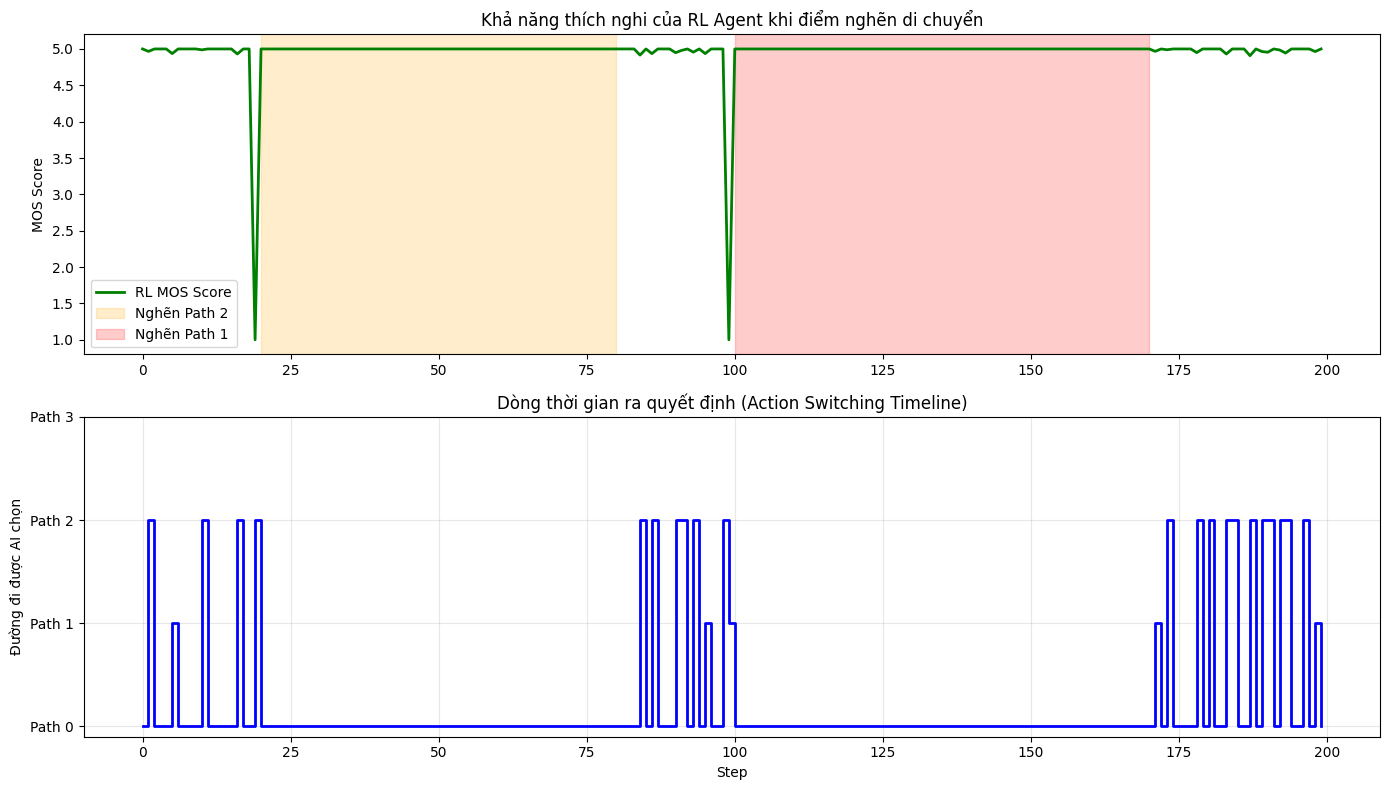

In [20]:
def evaluate_switching():
    obs, _ = env_dynamic.reset()
    history = {"mos": [], "actions": []}
    
    for _ in range(200):
        action = agent.select_action(obs, training=False)
        obs, reward, _, _, info = env_dynamic.step(action)
        history["mos"].append(info["mos"])
        history["actions"].append(action)
    return history

res = evaluate_switching()

plt.figure(figsize=(14, 8))

# Subplot 1: MOS Score
plt.subplot(2, 1, 1)
plt.plot(res["mos"], color='green', label='RL MOS Score', linewidth=2)
plt.axvspan(20, 80, color='orange', alpha=0.2, label='Nghẽn Path 2')
plt.axvspan(100, 170, color='red', alpha=0.2, label='Nghẽn Path 1')
plt.ylabel("MOS Score")
plt.title("Khả năng thích nghi của RL Agent khi điểm nghẽn di chuyển")
plt.legend()

# Subplot 2: Action Timeline (Đây là bằng chứng linh hoạt)
plt.subplot(2, 1, 2)
plt.step(range(200), res["actions"], where='post', color='blue', linewidth=2)
plt.yticks([0, 1, 2, 3], ['Path 0', 'Path 1', 'Path 2', 'Path 3'])
plt.ylabel("Đường đi được AI chọn")
plt.xlabel("Step")
plt.grid(True, alpha=0.3)
plt.title("Dòng thời gian ra quyết định (Action Switching Timeline)")

plt.tight_layout()
plt.show()

ép nó vào thế "cùng đường" ở cả hai lối đi chính, buộc nó phải tìm ra con đường dự phòng thứ 3 hoặc thứ 4.

Cập nhật Environment (Kịch bản 3 Giai đoạn linh hoạt)

Huấn luyện lại Agent cho "kịch bản khó"

Vẽ biểu đồ Đánh giá 3 giai đoạn 

Đang huấn luyện Agent vượt qua kịch bản 'Nghẽn chồng nghẽn' (1500 episodes)...
Huấn luyện xong!
Đang vẽ biểu đồ Đánh giá 3 giai đoạn...


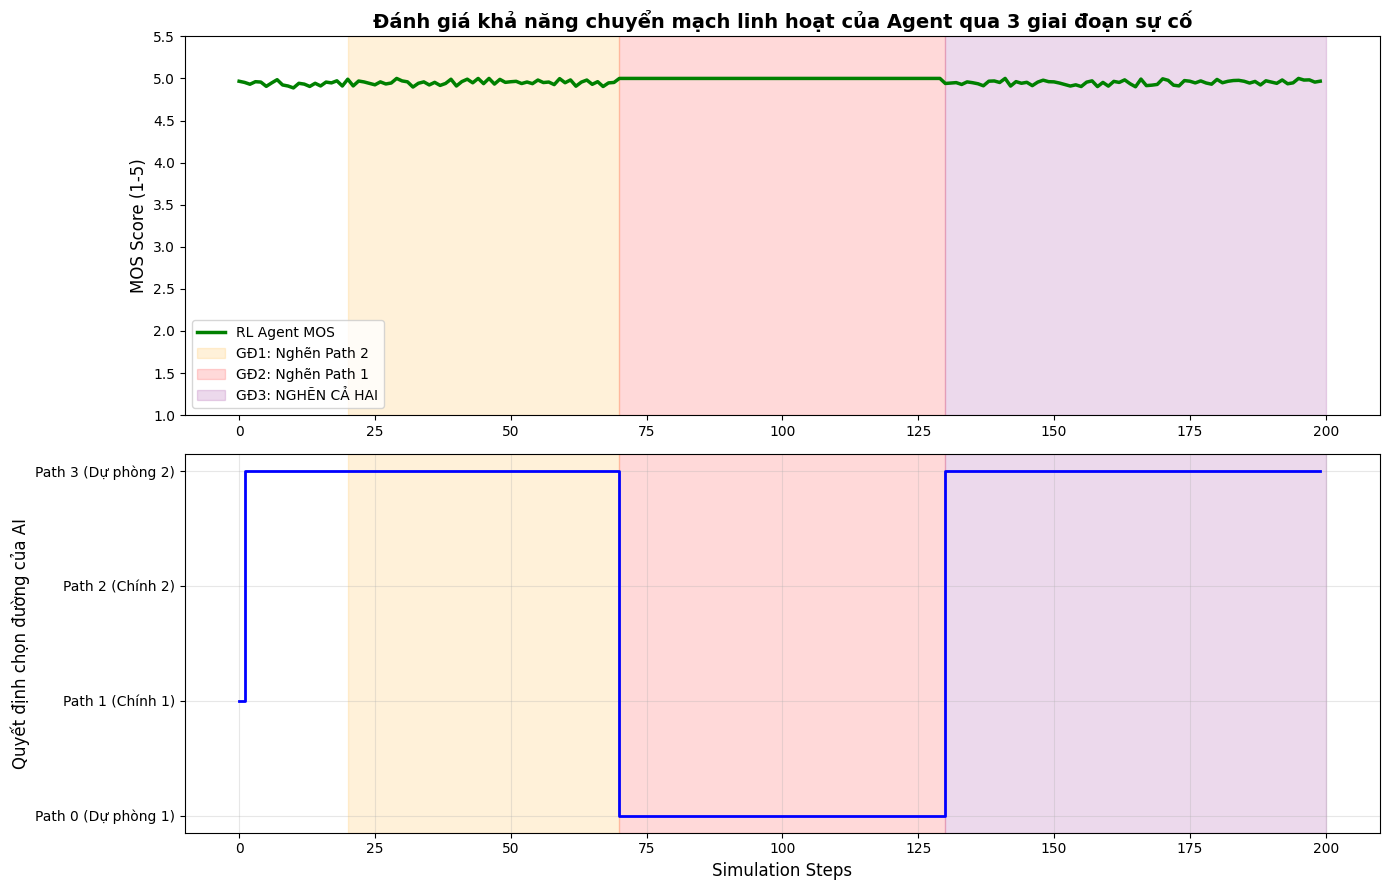

In [11]:
# =====================================================================
# 1. IMPORT CÁC THƯ VIỆN CẦN THIẾT
# =====================================================================
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt

# Cài đặt device (CPU/GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =====================================================================
# 2. ĐỊNH NGHĨA MÔI TRƯỜNG KỊCH BẢN 3 GIAI ĐOẠN (ULTIMATE)
# =====================================================================
class UltimateDynamicMosEnv(gym.Env):
    def __init__(self):
        super(UltimateDynamicMosEnv, self).__init__()
        self.max_steps = 200
        self.current_step = 0
        self.paths = {
            0: [1, 8],       # Path 0: u-w-z (Dự phòng 1)
            1: [2, 6, 9],    # Path 1: u-x-y-z (Đường chính)
            2: [0, 3, 8],    # Path 2: u-v-w-z (Đường chính 2)
            3:[2, 5, 8]     # Path 3: u-x-w-z (Dự phòng 2)
        }
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Box(low=0, high=500, shape=(20,), dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        return np.ones(20, dtype=np.float32) * 20.0, {}

    def step(self, action):
        self.current_step += 1
        # Trạng thái nền (Mạng rảnh)
        self.state = np.random.uniform(15.0, 25.0, 20).astype(np.float32)
        for i in range(10): self.state[i*2+1] = 0.0 

        # --- 3 GIAI ĐOẠN NGHẼN MẠNG ---
        # Giai đoạn 1 (20-70): Nghẽn Path 2 (Link 3) -> Nên chọn Path 1
        if 20 <= self.current_step < 70:
            self.state[3*2] = 350.0; self.state[3*2+1] = 20.0
            
        # Giai đoạn 2 (70-130): Nghẽn Path 1 (Link 6) -> Nên chọn Path 2
        elif 70 <= self.current_step < 130:
            self.state[6*2] = 350.0; self.state[6*2+1] = 20.0
            
        # Giai đoạn 3 (130-200): Nghẽn cả Path 1 và 2 -> Buộc phải chọn Path 0 hoặc 3
        elif self.current_step >= 130:
            self.state[3*2] = 350.0; self.state[3*2+1] = 20.0 
            self.state[6*2] = 350.0; self.state[6*2+1] = 20.0 

        # Tính MOS
        links = self.paths[action]
        d = sum([self.state[i*2] for i in links])
        p_succ = np.prod([(1 - self.state[i*2+1]/100) for i in links])
        l = (1 - p_succ) * 100
        mos = float(np.clip(5.0 - (max(0, d-50)*0.005) - (l*0.2), 1.0, 5.0))
        
        return self.state, mos, False, self.current_step >= self.max_steps, {"mos": mos}

# =====================================================================
# 3. ĐỊNH NGHĨA AGENT PYTORCH (Đã bỏ One-hot encoding)
# =====================================================================
class ReplayBuffer:
    def __init__(self, capacity=10000):
        self.buffer = deque(maxlen=capacity)
    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))
    def sample(self, batch_size):
        batch = random.sample(self.buffer, min(batch_size, len(self.buffer)))
        states = torch.tensor(np.array([t[0] for t in batch]), dtype=torch.float32, device=device)
        actions = torch.tensor(np.array([t[1] for t in batch]), dtype=torch.int64, device=device)
        rewards = torch.tensor(np.array([t[2] for t in batch]), dtype=torch.float32, device=device)
        next_states = torch.tensor(np.array([t[3] for t in batch]), dtype=torch.float32, device=device)
        dones = torch.tensor(np.array([t[4] for t in batch]), dtype=torch.float32, device=device)
        return states, actions, rewards, next_states, dones
    def __len__(self): return len(self.buffer)

class DQNNetwork(nn.Module):
    def __init__(self, state_size=20, action_size=4):
        super(DQNNetwork, self).__init__()
        self.fc1 = nn.Linear(state_size, 128)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()
        self.out = nn.Linear(64, action_size)
    def forward(self, state):
        return self.out(self.relu2(self.fc2(self.relu1(self.fc1(state)))))

class DQNAgent:
    def __init__(self, state_size=20, action_size=4):
        self.action_size = action_size
        self.gamma = 0.99
        self.epsilon = 1.0
        self.epsilon_min = 0.05
        self.epsilon_decay = 0.995
        
        self.q_network = DQNNetwork(state_size, action_size).to(device)
        self.target_network = DQNNetwork(state_size, action_size).to(device)
        self.target_network.load_state_dict(self.q_network.state_dict())
        self.optimizer = optim.Adam(self.q_network.parameters(), lr=1e-3)
        self.loss_fn = nn.MSELoss()
        self.replay_buffer = ReplayBuffer(10000)
        self.update_counter = 0

    def select_action(self, state, training=True):
        if training and random.random() < self.epsilon:
            return random.randint(0, self.action_size - 1)
        state_tensor = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
        with torch.no_grad():
            return self.q_network(state_tensor).argmax(dim=1).item()

    def train_step(self, batch_size=64):
        if len(self.replay_buffer) < batch_size: return
        states, actions, rewards, next_states, dones = self.replay_buffer.sample(batch_size)
        q_values = self.q_network(states).gather(1, actions.unsqueeze(1)).squeeze(1)
        with torch.no_grad():
            next_q_values = self.target_network(next_states).max(dim=1)[0]
            target_q_values = rewards + self.gamma * next_q_values * (1 - dones)
        loss = self.loss_fn(q_values, target_q_values)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        self.update_counter += 1
        if self.update_counter % 100 == 0:
            self.target_network.load_state_dict(self.q_network.state_dict())

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

# =====================================================================
# 4. HUẤN LUYỆN (TRAINING)
# =====================================================================
env_ultimate = UltimateDynamicMosEnv()
agent = DQNAgent(state_size=20, action_size=4)

print("Đang huấn luyện Agent vượt qua kịch bản 'Nghẽn chồng nghẽn' (1500 episodes)...")
for episode in range(1500):
    state, _ = env_ultimate.reset()
    done = False
    while not done:
        action = agent.select_action(state)
        next_obs, reward, term, trunc, _ = env_ultimate.step(action)
        done = term or trunc
        agent.replay_buffer.push(state, action, reward, next_obs, done)
        agent.train_step(batch_size=64)
        state = next_obs
    agent.decay_epsilon()
print("Huấn luyện xong!")

# Lưu mô hình
torch.save(agent.q_network.state_dict(), "dqn_pytorch_ultimate.pth")

# =====================================================================
# 5. ĐÁNH GIÁ & VẼ BIỂU ĐỒ (VISUALIZATION)
# =====================================================================
print("Đang vẽ biểu đồ Đánh giá 3 giai đoạn...")
obs, _ = env_ultimate.reset()
history = {"mos": [], "actions":[]}
for _ in range(200):
    action = agent.select_action(obs, training=False)
    obs, reward, _, _, info = env_ultimate.step(action)
    history["mos"].append(info["mos"])
    history["actions"].append(action)

plt.figure(figsize=(14, 9))

# Biểu đồ 1: MOS
plt.subplot(2, 1, 1)
plt.plot(history["mos"], color='green', label='RL Agent MOS', linewidth=2.5)
plt.axvspan(20, 70, color='orange', alpha=0.15, label='GĐ1: Nghẽn Path 2')
plt.axvspan(70, 130, color='red', alpha=0.15, label='GĐ2: Nghẽn Path 1')
plt.axvspan(130, 200, color='purple', alpha=0.15, label='GĐ3: NGHẼN CẢ HAI')
plt.ylabel("MOS Score (1-5)", fontsize=12)
plt.ylim(1, 5.5)
plt.title("Đánh giá khả năng chuyển mạch linh hoạt của Agent qua 3 giai đoạn sự cố", fontsize=14, fontweight='bold')
plt.legend(loc='lower left')

# Biểu đồ 2: Actions
plt.subplot(2, 1, 2)
plt.step(range(200), history["actions"], where='post', color='blue', linewidth=2)
plt.axvspan(20, 70, color='orange', alpha=0.15)
plt.axvspan(70, 130, color='red', alpha=0.15)
plt.axvspan(130, 200, color='purple', alpha=0.15)
plt.yticks([0, 1, 2, 3],['Path 0 (Dự phòng 1)', 'Path 1 (Chính 1)', 'Path 2 (Chính 2)', 'Path 3 (Dự phòng 2)'])
plt.ylabel("Quyết định chọn đường của AI", fontsize=12)
plt.xlabel("Simulation Steps", fontsize=12)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()